# Customer Behaviour Analysis

## Objective

This notebook investigates customer purchasing behaviour using order-level data. The analysis focuses on purchase frequency, recency, monetary value, customer segmentation, and differences in customer activity.

## Key Questions

- How recently have customers placed orders?
- How frequently do customers place orders?
- How much have customers spent according to recorded order totals?
- Which customer segments can be identified using RFM analysis?
- How do purchasing patterns differ across customer tiers?

## Methodology

- Calculate customer-level metrics from the orders table rather than relying on potentially inconsistent customer summary fields.
- Inspect order statuses and define the scope of monetary calculations.
- Build Recency, Frequency, and Monetary (RFM) features.
- Explore customer distributions and create interpretable customer segments.
- Document assumptions, data limitations, and potential biases.

## Limitations

Order totals across all statuses do not necessarily represent realized revenue. RFM results will depend on the selected order statuses and observation date. Customer-level metrics will be interpreted as descriptive indicators rather than causal evidence.

In [1]:

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from ecommerce_analysis.customer_segmentation import (
    assign_customer_segments,
    build_rfm_features,
    score_rfm,
    summarize_customer_segments,
)

customers = pd.read_csv(RAW_DATA_DIR / "customers.csv")
orders = pd.read_csv(RAW_DATA_DIR / "orders.csv")

orders["placed_at"] = pd.to_datetime(
    orders["placed_at"],
    errors="coerce",
    utc=True,
)

print("CUSTOMER BEHAVIOUR DATA")
print("-" * 40)
print(f"Customers: {customers.shape}")
print(f"Orders: {orders.shape}")
print(f"Unique customer IDs: {customers['id'].nunique()}")
print(f"Unique order IDs: {orders['id'].nunique()}")


CUSTOMER BEHAVIOUR DATA
----------------------------------------
Customers: (800, 13)
Orders: (3000, 21)
Unique customer IDs: 800
Unique order IDs: 3000


In [2]:
# Investigate order statuses before building RFM features

status_summary = (
    orders.groupby("status", dropna=False)
    .agg(
        order_count=("id", "nunique"),
        customer_count=("customer_id", "nunique"),
        total_order_value=("total", "sum"),
        median_order_total=("total", "median")
    )
    .sort_values("order_count", ascending=False)
)

status_summary["percentage_of_orders"] = (
    status_summary["order_count"] / orders["id"].nunique() * 100
)

display(
    status_summary.style.format({
        "total_order_value": "${:,.2f}",
        "median_order_total": "${:,.2f}",
        "percentage_of_orders": "{:.2f}%"
    })
)

print("\nMissing customer IDs:", orders["customer_id"].isna().sum())
print("Missing placed_at dates:", orders["placed_at"].isna().sum())
print("Missing order totals:", orders["total"].isna().sum())

print(
    "\nUnique customers with delivered orders:",
    orders.loc[orders["status"] == "delivered", "customer_id"].nunique()
)

,order_count,customer_count,total_order_value,median_order_total,percentage_of_orders
status,,,,,
delivered,2675,766,"$3,798,097.73",$790.20,89.17%
cancelled,173,155,"$275,120.69",$802.63,5.77%
refunded,104,97,"$120,636.09",$639.18,3.47%
shipped,32,31,"$68,924.42","$1,389.72",1.07%
paid,9,9,"$9,086.16",$950.95,0.30%
pending,7,7,"$8,415.52",$849.77,0.23%



Missing customer IDs: 0
Missing placed_at dates: 0
Missing order totals: 0

Unique customers with delivered orders: 766


In [3]:

# Build customer-level RFM features using the reusable module

rfm = build_rfm_features(
    customers=customers,
    orders=orders,
)

observation_date = rfm.attrs["observation_date"]

print("RFM OBSERVATION DATE:", observation_date)
print("Total customers:", len(rfm))
print(
    "Customers with delivered orders:",
    int(rfm["has_delivered_order"].sum()),
)
print(
    "Customers without delivered orders:",
    int((~rfm["has_delivered_order"]).sum()),
)

print("\nRFM NUMERICAL SUMMARY")
display(
    rfm[["recency_days", "frequency", "monetary"]]
    .describe()
    .round(2)
)

print("\nSAMPLE RFM RECORDS")
display(rfm.head(10))


RFM OBSERVATION DATE: 2026-08-30 00:00:00+00:00
Total customers: 800
Customers with delivered orders: 766
Customers without delivered orders: 34

RFM NUMERICAL SUMMARY


,recency_days,frequency,monetary
count,766.00,766.00,766.00
mean,97.05,3.49,4958.35
std,83.38,1.83,4191.62
min,1.00,1.00,18.34
25%,29.25,2.00,1696.70
50%,71.00,3.00,3917.60
75%,147.00,5.00,6956.82
max,361.00,12.00,30063.98



SAMPLE RFM RECORDS


,customer_id,tier,last_order_date,recency_days,frequency,monetary,has_delivered_order
0,1,gold,2026-03-29 09:15:14+00:00,154.0,4.0,5419.75,True
1,2,standard,2026-04-27 11:32:11+00:00,125.0,4.0,11795.61,True
2,3,standard,2026-05-14 06:01:31+00:00,108.0,5.0,3138.05,True
3,4,standard,2025-10-17 17:18:36+00:00,317.0,2.0,468.40,True
4,5,platinum,2026-04-05 08:26:32+00:00,147.0,3.0,3787.59,True
5,6,standard,NaT,NaN,NaN,NaN,False
6,7,standard,2026-08-09 22:41:59+00:00,21.0,4.0,4967.00,True
7,8,standard,2026-03-23 17:02:46+00:00,160.0,2.0,1765.24,True
8,9,silver,2026-07-12 22:43:31+00:00,49.0,2.0,612.14,True
9,10,gold,2026-08-13 21:22:23+00:00,17.0,4.0,5882.65,True


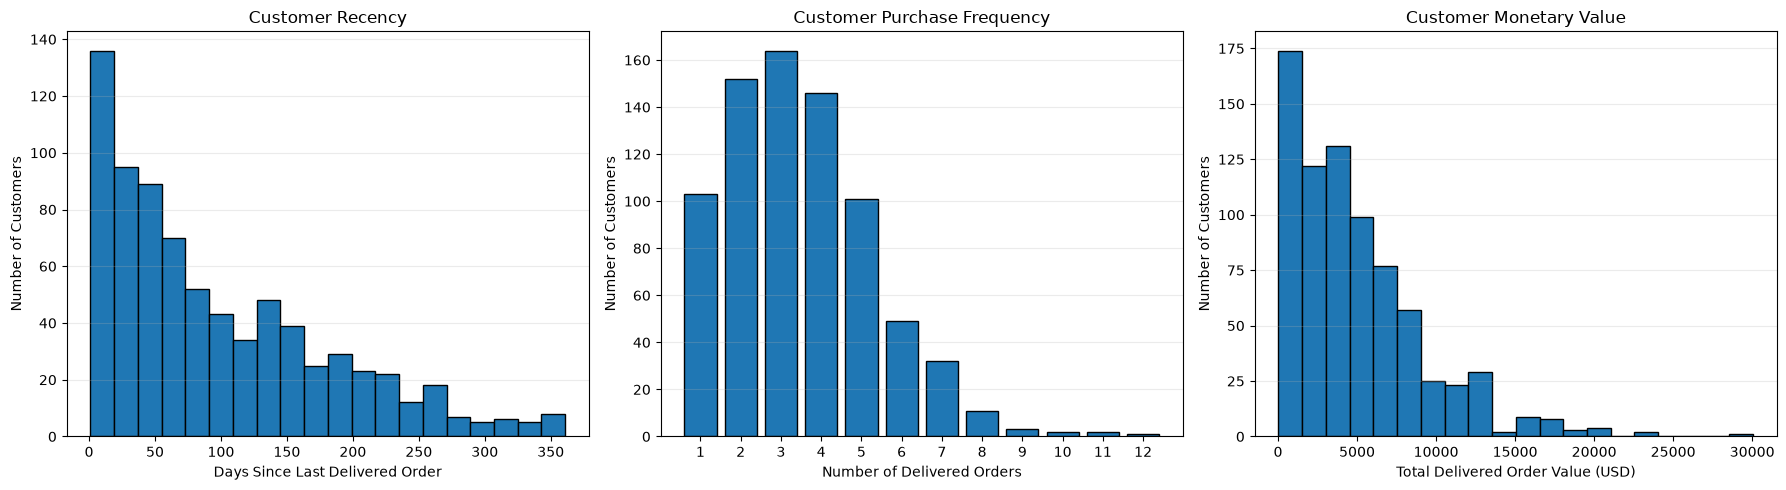

In [4]:
# Visualize RFM distributions for customers with delivered orders

rfm_active = rfm.loc[rfm["has_delivered_order"]].copy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Recency distribution
axes[0].hist(
    rfm_active["recency_days"],
    bins=20,
    edgecolor="black"
)
axes[0].set_title("Customer Recency")
axes[0].set_xlabel("Days Since Last Delivered Order")
axes[0].set_ylabel("Number of Customers")
axes[0].grid(axis="y", alpha=0.25)

# Frequency distribution
frequency_counts = rfm_active["frequency"].value_counts().sort_index()

axes[1].bar(
    frequency_counts.index.astype(int),
    frequency_counts.values,
    edgecolor="black"
)
axes[1].set_title("Customer Purchase Frequency")
axes[1].set_xlabel("Number of Delivered Orders")
axes[1].set_ylabel("Number of Customers")
axes[1].set_xticks(frequency_counts.index.astype(int))
axes[1].grid(axis="y", alpha=0.25)

# Monetary distribution
axes[2].hist(
    rfm_active["monetary"],
    bins=20,
    edgecolor="black"
)
axes[2].set_title("Customer Monetary Value")
axes[2].set_xlabel("Total Delivered Order Value (USD)")
axes[2].set_ylabel("Number of Customers")
axes[2].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [5]:

# Cell 6: RFM Scoring

rfm = score_rfm(rfm)

rfm_active = rfm.loc[rfm["has_delivered_order"]].copy()

print("RFM SCORE SUMMARY")
display(
    rfm_active[
        ["R_score", "F_score", "M_score", "RFM_score"]
    ].describe().round(2)
)

print("\nCOMBINED RFM SCORE DISTRIBUTION")
display(
    rfm_active["RFM_score"]
    .value_counts()
    .sort_index()
    .to_frame("customer_count")
)

print("\nMOST COMMON RFM CODES")
display(
    rfm_active["RFM_segment_code"]
    .value_counts()
    .head(10)
    .to_frame("customer_count")
)

print("\nSAMPLE SCORED CUSTOMERS")
display(
    rfm_active[
        [
            "customer_id",
            "recency_days",
            "frequency",
            "monetary",
            "R_score",
            "F_score",
            "M_score",
            "RFM_score",
            "RFM_segment_code",
        ]
    ].head(10)
)


RFM SCORE SUMMARY


,R_score,F_score,M_score,RFM_score
count,766.0,766.0,766.0,766.0
mean,2.5,2.5,2.5,7.5
std,1.12,1.12,1.12,2.62
min,1.0,1.0,1.0,3.0
25%,1.25,1.25,1.25,5.0
50%,2.5,2.5,2.5,8.0
75%,3.75,3.75,3.75,10.0
max,4.0,4.0,4.0,12.0



COMBINED RFM SCORE DISTRIBUTION


,customer_count
RFM_score,
3,60
4,55
5,89
6,89
7,87
8,86
9,90
10,94
11,73



MOST COMMON RFM CODES


,customer_count
RFM_segment_code,
111,60
444,43
344,34
443,28
122,22
222,21
311,21
223,21
112,20



SAMPLE SCORED CUSTOMERS


,customer_id,recency_days,frequency,monetary,R_score,F_score,M_score,RFM_score,RFM_segment_code
0,1,154.0,4.0,5419.75,1,3,3,7,133
1,2,125.0,4.0,11795.61,2,3,4,9,234
2,3,108.0,5.0,3138.05,2,3,2,7,232
3,4,317.0,2.0,468.40,1,1,1,3,111
4,5,147.0,3.0,3787.59,2,2,2,6,222
6,7,21.0,4.0,4967.00,4,3,3,10,433
7,8,160.0,2.0,1765.24,1,1,2,4,112
8,9,49.0,2.0,612.14,3,1,1,5,311
9,10,17.0,4.0,5882.65,4,3,3,10,433
10,11,139.0,1.0,8259.23,2,1,4,7,214


In [6]:

# Cell 7: Customer Segmentation

rfm = assign_customer_segments(rfm)

rfm_active = rfm.loc[
    rfm["has_delivered_order"]
].copy()

segment_summary = summarize_customer_segments(rfm)

print("CUSTOMER SEGMENT SUMMARY")
display(
    segment_summary.style.format({
        "median_recency_days": "{:.0f}",
        "median_frequency": "{:.1f}",
        "median_monetary": "${:,.2f}",
        "average_rfm_score": "{:.2f}",
        "customer_percentage": "{:.2f}%",
    })
)

print("\nSegment total:", segment_summary["customer_count"].sum())
print("Customers with delivered orders:", len(rfm_active))

print("\nALL CUSTOMER SEGMENTS")
display(
    rfm["customer_segment"]
    .value_counts(dropna=False)
    .to_frame("customer_count")
)


CUSTOMER SEGMENT SUMMARY


,customer_count,median_recency_days,median_frequency,median_monetary,average_rfm_score,customer_percentage
customer_segment,,,,,,
Hibernating / Low Engagement,253,160,2.0,"$2,078.94",4.75,33.03%
Champions,189,28,5.0,"$7,321.70",10.76,24.67%
At Risk - Previously Frequent,130,125,4.0,"$5,402.47",8.01,16.97%
Recent / Potential Customers,130,34,2.0,"$1,975.13",7.07,16.97%
Loyal Active Customers,64,30,4.0,"$2,736.13",8.61,8.36%



Segment total: 766
Customers with delivered orders: 766

ALL CUSTOMER SEGMENTS


,customer_count
customer_segment,
Hibernating / Low Engagement,253
Champions,189
At Risk - Previously Frequent,130
Recent / Potential Customers,130
Loyal Active Customers,64
No Delivered Orders,34


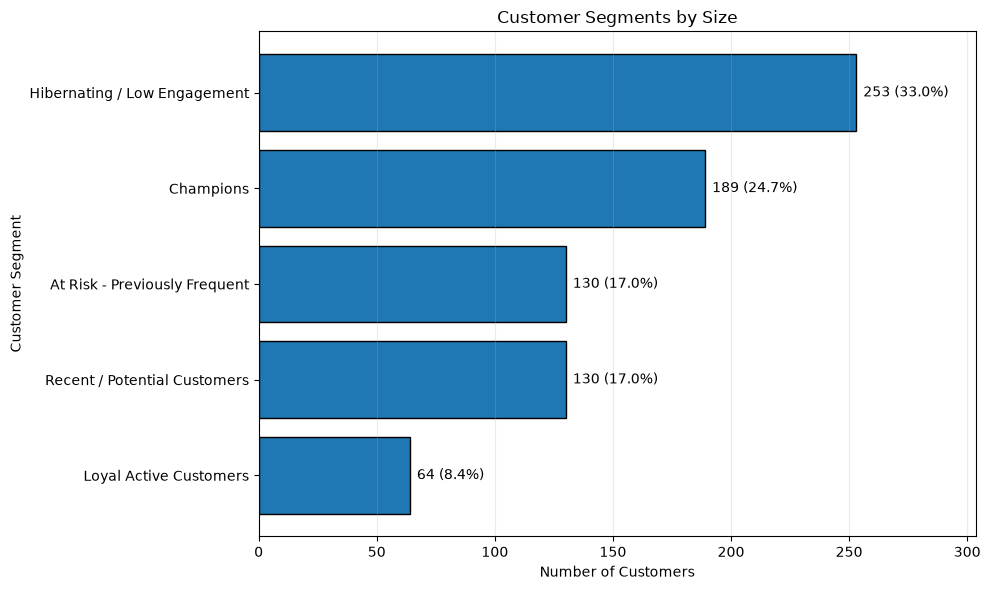

In [7]:
# Visualize customer segment sizes

segment_counts = (
    rfm_active["customer_segment"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    segment_counts.index,
    segment_counts.values,
    edgecolor="black"
)

plt.title("Customer Segments by Size")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

for bar, count in zip(bars, segment_counts.values):
    percentage = count / len(rfm_active) * 100
    plt.text(
        bar.get_width() + 3,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({percentage:.1f}%)",
        va="center"
    )

plt.xlim(0, segment_counts.max() * 1.2)
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

customer_segment,At Risk - Previously Frequent,Champions,Hibernating / Low Engagement,Loyal Active Customers,Recent / Potential Customers
tier,,,,,
gold,19,32,34,10,11
platinum,8,12,14,5,8
silver,25,49,45,14,27
standard,78,96,160,35,84



PERCENTAGE WITHIN EACH TIER (%)


customer_segment,At Risk - Previously Frequent,Champions,Hibernating / Low Engagement,Loyal Active Customers,Recent / Potential Customers
tier,,,,,
gold,17.92,30.19,32.08,9.43,10.38
platinum,17.02,25.53,29.79,10.64,17.02
silver,15.62,30.63,28.12,8.75,16.88
standard,17.22,21.19,35.32,7.73,18.54


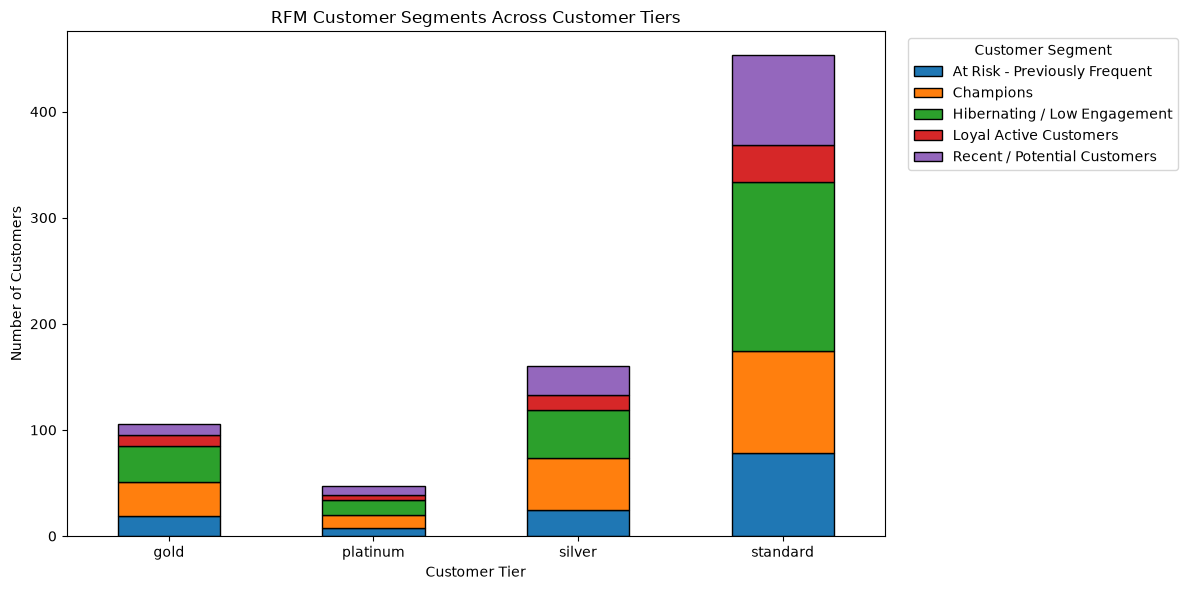

In [8]:
# Compare customer tiers with RFM segments

tier_segment_counts = pd.crosstab(
    rfm_active["tier"],
    rfm_active["customer_segment"]
)

display(tier_segment_counts)

print("\nPERCENTAGE WITHIN EACH TIER (%)")

tier_segment_percentages = pd.crosstab(
    rfm_active["tier"],
    rfm_active["customer_segment"],
    normalize="index"
) * 100

display(tier_segment_percentages.round(2))

# Visualize the comparison
tier_segment_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    edgecolor="black"
)

plt.title("RFM Customer Segments Across Customer Tiers")
plt.xlabel("Customer Tier")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(
    title="Customer Segment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

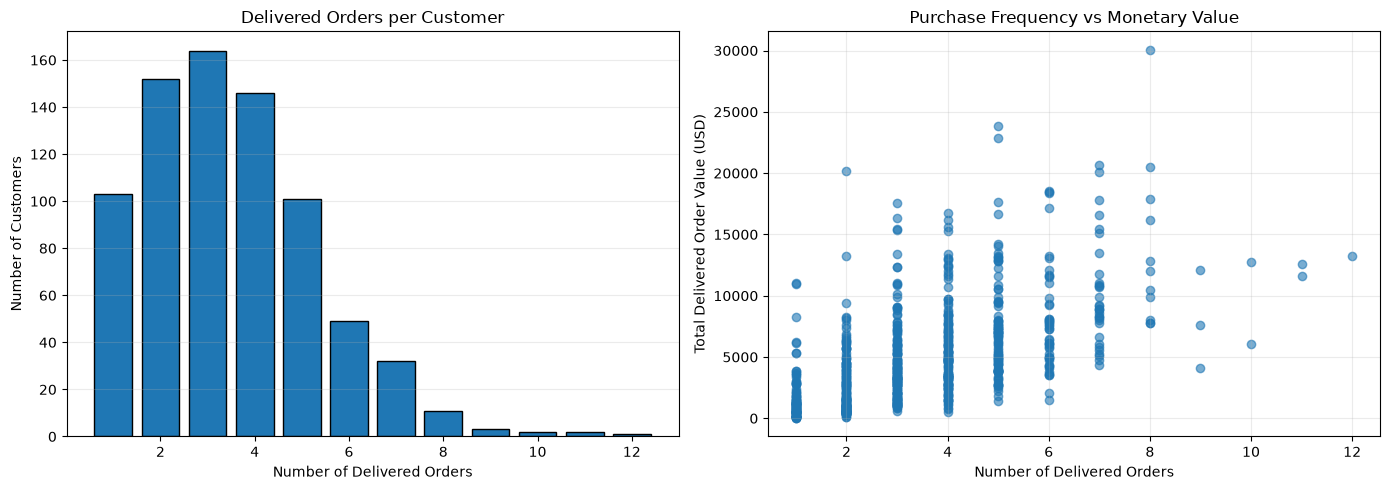

Spearman correlation between frequency and monetary value: 0.649


In [9]:
# Analyze the relationship between purchase frequency and monetary value

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Purchase frequency distribution
frequency_counts = rfm_active["frequency"].value_counts().sort_index()

axes[0].bar(
    frequency_counts.index,
    frequency_counts.values,
    edgecolor="black"
)
axes[0].set_title("Delivered Orders per Customer")
axes[0].set_xlabel("Number of Delivered Orders")
axes[0].set_ylabel("Number of Customers")
axes[0].grid(axis="y", alpha=0.25)

# Frequency vs monetary value
axes[1].scatter(
    rfm_active["frequency"],
    rfm_active["monetary"],
    alpha=0.6
)
axes[1].set_title("Purchase Frequency vs Monetary Value")
axes[1].set_xlabel("Number of Delivered Orders")
axes[1].set_ylabel("Total Delivered Order Value (USD)")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Correlation analysis
frequency_monetary_corr = rfm_active[
    ["frequency", "monetary"]
].corr(method="spearman").iloc[0, 1]

print(
    "Spearman correlation between frequency and monetary value:",
    round(frequency_monetary_corr, 3)
)

# Customer Behaviour Analysis — Key Findings

## 1. Order Status and Customer Activity

The dataset contains 3,000 orders from 800 customers. Of these, 2,675 orders (89.17%) were marked as delivered. A total of 766 unique customers had at least one delivered order, while 34 customers had no delivered orders.

For customer behaviour analysis, only delivered orders were used to calculate RFM metrics. This reduces the influence of cancelled, refunded, pending, paid, and shipped orders on the analysis.

## 2. RFM Analysis

RFM analysis was performed using:

- **Recency:** Days since the customer's most recent delivered order. Lower values indicate more recent activity.
- **Frequency:** Number of delivered orders per customer.
- **Monetary:** Sum of the recorded totals of delivered orders per customer.

Among the 766 customers with delivered orders, median recency was 71 days, median frequency was 3 orders, and median monetary value was approximately $3,917.60.

The RFM scores were calculated using quartile-based rankings. These scores are relative to this dataset, and tied values may receive different scores because ranking was used to create balanced groups.

## 3. Customer Segmentation

Customers with delivered orders were assigned to five rule-based segments:

- **Hibernating / Low Engagement:** 253 customers (33.03%)
- **Champions:** 189 customers (24.67%)
- **At Risk — Previously Frequent:** 130 customers (16.97%)
- **Recent / Potential Customers:** 130 customers (16.97%)
- **Loyal Active Customers:** 64 customers (8.36%)

Hibernating / Low Engagement was the largest segment, while Loyal Active Customers was the smallest. These segments may help identify customers for re-engagement or retention campaigns, but the definitions are heuristic and have not been independently validated.

## 4. Customer Tier Comparison

Hibernating / Low Engagement represented 32.08% of Gold customers and 35.32% of Standard customers. Therefore, a higher recorded customer tier did not necessarily correspond to more recent purchasing activity in this dataset.

These results describe an observed association and do not establish why customers fall into particular segments.

## 5. Purchase Frequency and Monetary Value

The Spearman correlation between delivered-order frequency and monetary value was **0.649**, indicating a moderately strong positive monotonic association. Customers with more delivered orders generally tended to have higher cumulative delivered-order values.

This relationship is expected to some extent because monetary value accumulates across orders. It should not be interpreted as evidence that increasing order frequency alone causes higher customer value.

## 6. Limitations

- The analysis uses only delivered orders for RFM calculations.
- The 34 customers without delivered orders have missing RFM metrics rather than zero-valued RFM scores.
- Monetary value is based on recorded order totals and should not automatically be interpreted as net revenue or profit.
- RFM scores and segment definitions depend on the selected observation date, scoring method, and rules.
- Customer tier labels are compared descriptively; this analysis does not establish a causal relationship between tier and purchasing behaviour.
- The results describe this dataset and may not generalise to other businesses or time periods.

## Conclusion

The analysis identified five customer behaviour segments and found a positive association between delivered-order frequency and cumulative monetary value. The largest segment consisted of customers with relatively low engagement, suggesting a potential area for further investigation. These findings can inform future customer retention and re-engagement analysis, subject to the limitations above.